COMPREHENSIVE XAI ANALYSIS (INCLUDING HYBRID)


C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



CLASS 1: Merging Galaxies
Real: 50, GAN: 50, Diffusion: 50, Hybrid: 50

Morphology Analysis:
  Real:    1.909
  GAN:     1.803 (Δ5.5%)
  Diff:    1.963 (Δ2.8%)
  Hybrid:  1.817 (Δ4.8%)

Grad-CAM Analysis:


C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\torch\nn\modules\module.py:1842: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)
C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\scipy\spatial\distance.py:685: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / math.sqrt(uu * vv)


  GAN similarity:    nan
  Diff similarity:   0.205
  Hybrid similarity: 0.227


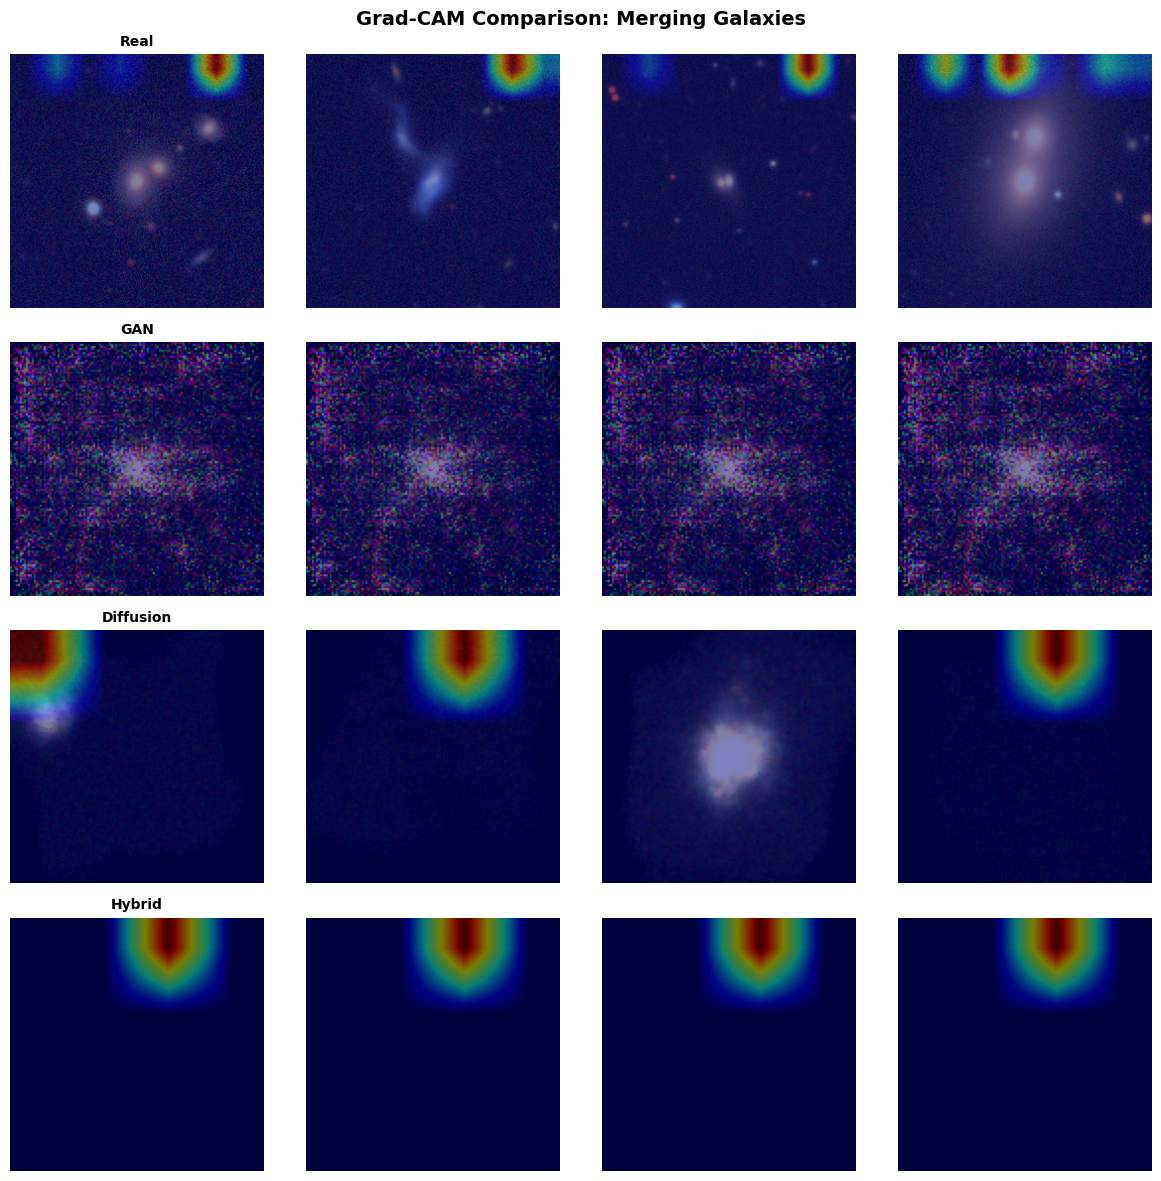


Feature Space Analysis:
  GAN separation:    384.694
  Diff separation:   300.022
  Hybrid separation: 340.595


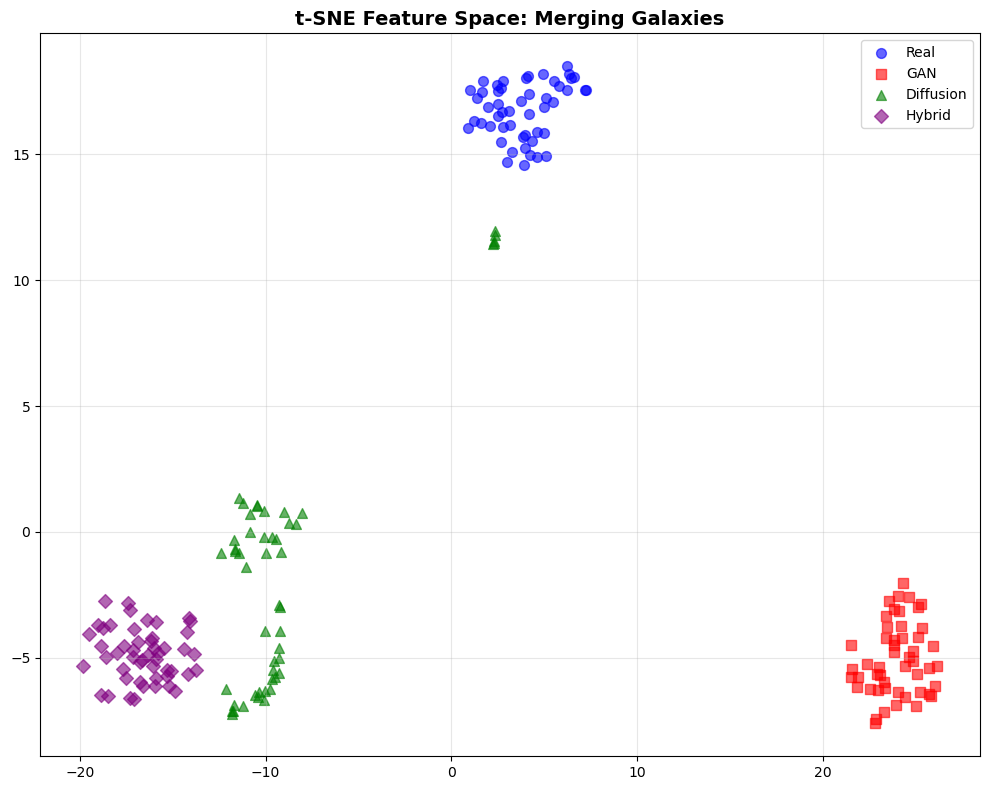


CLASS 4: Cigar Shaped Smooth Galaxies
Real: 31, GAN: 50, Diffusion: 50, Hybrid: 50

Morphology Analysis:
  Real:    1.538
  GAN:     1.239 (Δ19.5%)
  Diff:    1.848 (Δ20.1%)
  Hybrid:  1.811 (Δ17.7%)

Grad-CAM Analysis:


C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\torch\nn\modules\module.py:1842: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


  GAN similarity:    nan
  Diff similarity:   0.421
  Hybrid similarity: 0.398


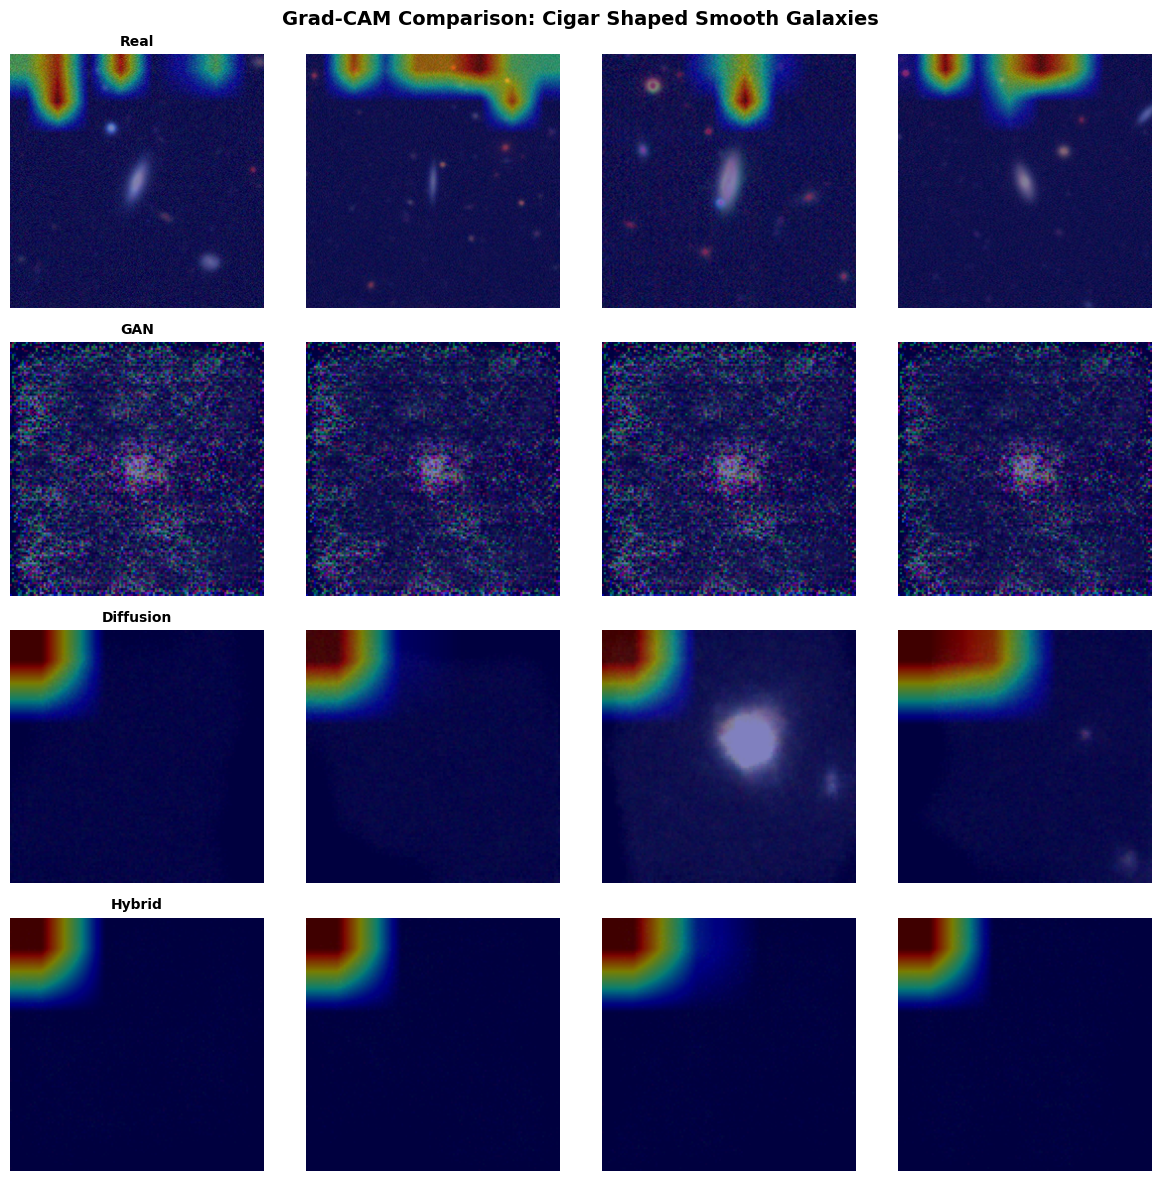


Feature Space Analysis:
  GAN separation:    465.549
  Diff separation:   326.276
  Hybrid separation: 412.947


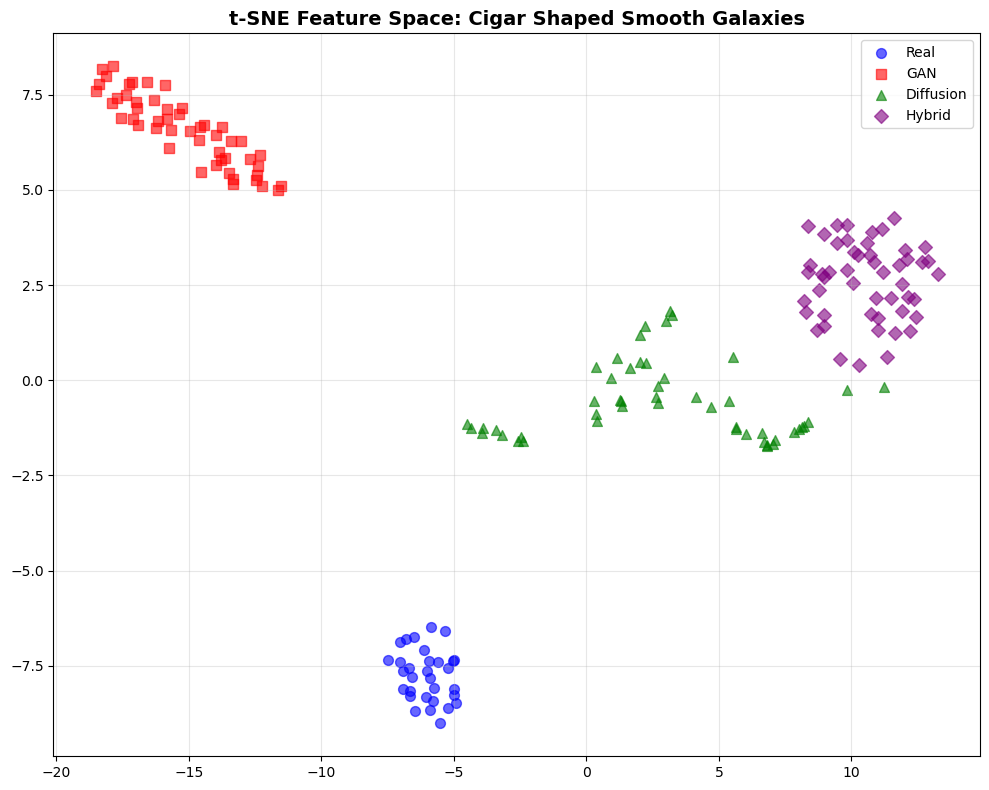


CLASS 8: Edge-on without Bulge
Real: 50, GAN: 50, Diffusion: 50, Hybrid: 50

Morphology Analysis:
  Real:    1.733
  GAN:     1.642 (Δ5.2%)
  Diff:    1.846 (Δ6.5%)
  Hybrid:  1.275 (Δ26.4%)

Grad-CAM Analysis:


C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\torch\nn\modules\module.py:1842: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


  GAN similarity:    0.795
  Diff similarity:   0.781
  Hybrid similarity: 0.829


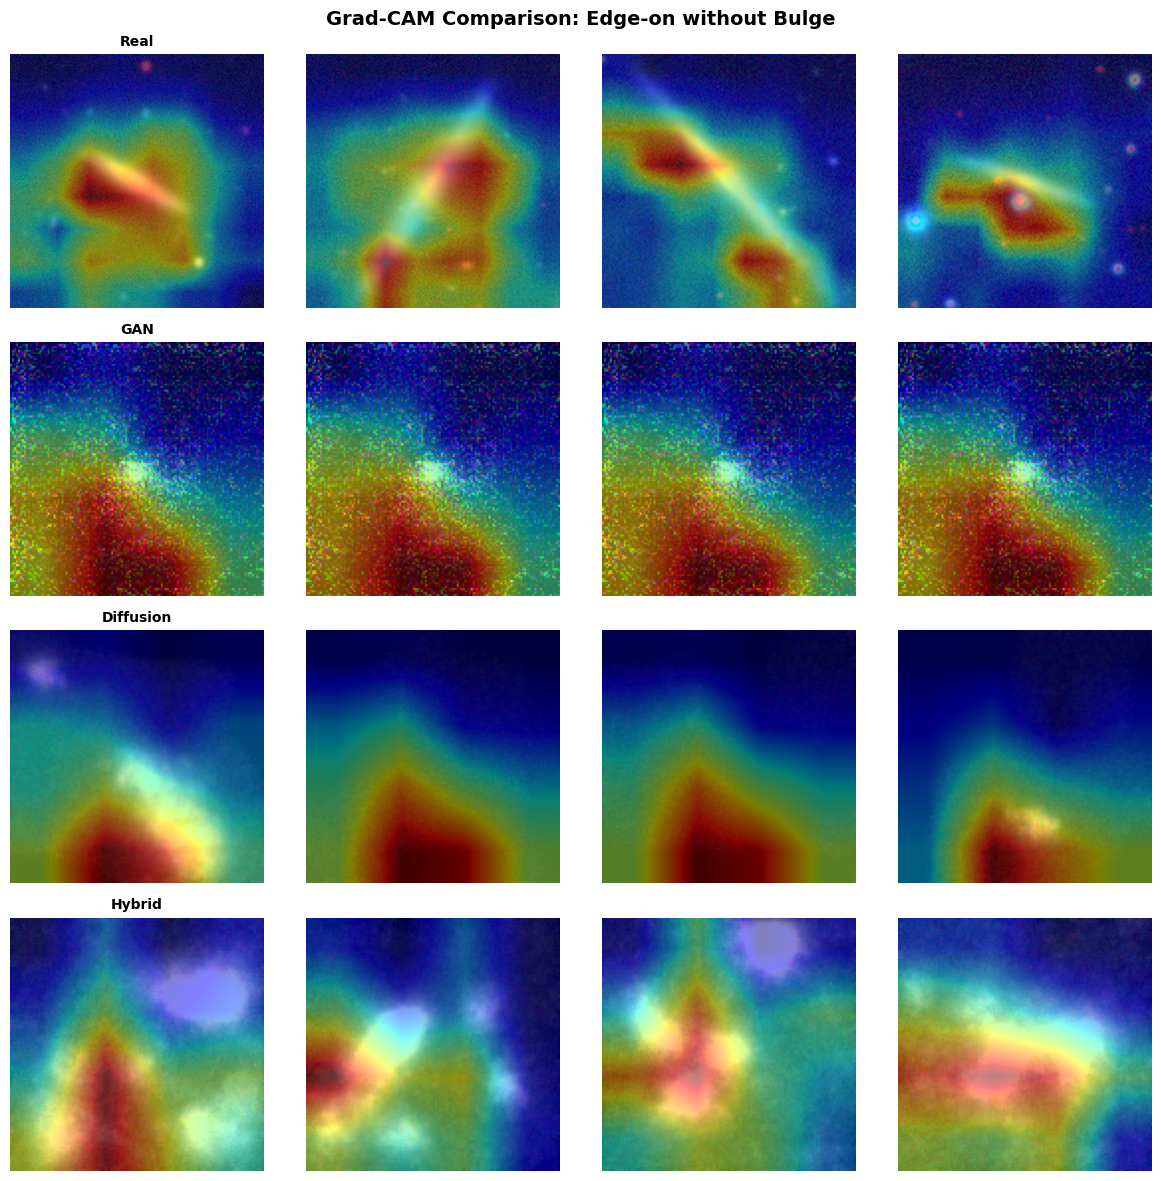


Feature Space Analysis:
  GAN separation:    323.484
  Diff separation:   315.871
  Hybrid separation: 341.237


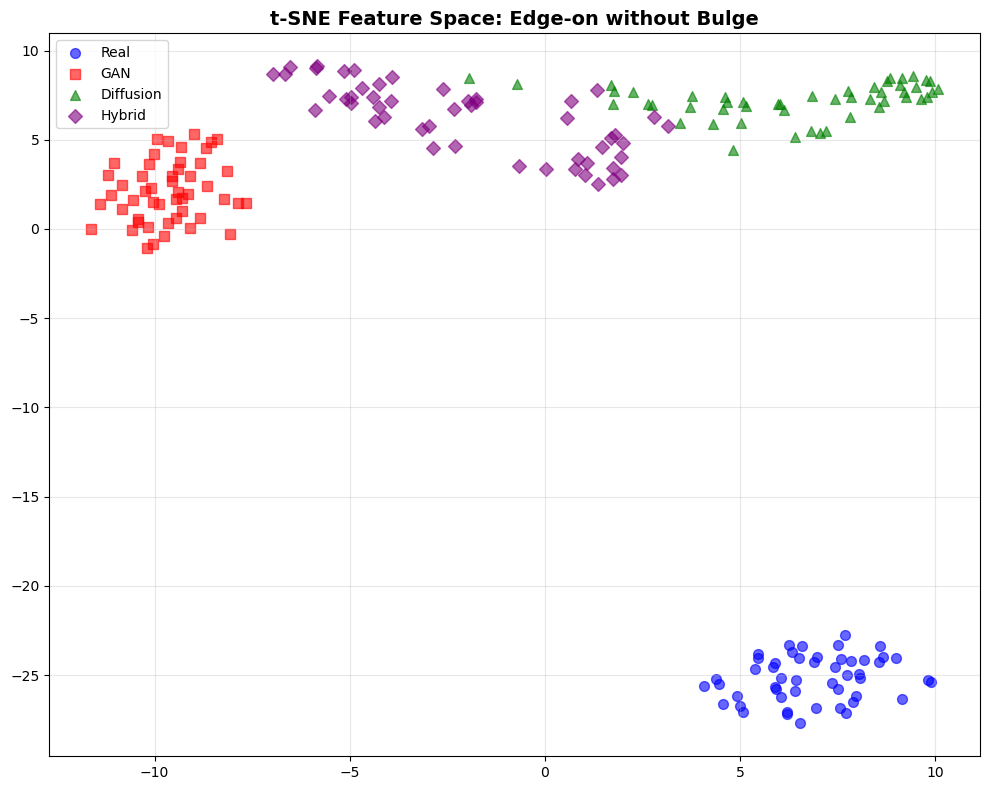


CLASS 9: Edge-on with Bulge
Real: 50, GAN: 50, Diffusion: 50, Hybrid: 50

Morphology Analysis:
  Real:    1.735
  GAN:     1.278 (Δ26.4%)
  Diff:    1.735 (Δ0.0%)
  Hybrid:  1.407 (Δ18.9%)

Grad-CAM Analysis:


C:\Users\ma25751\AppData\Local\anaconda3\Lib\site-packages\torch\nn\modules\module.py:1842: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


  GAN similarity:    0.566
  Diff similarity:   0.740
  Hybrid similarity: 0.630


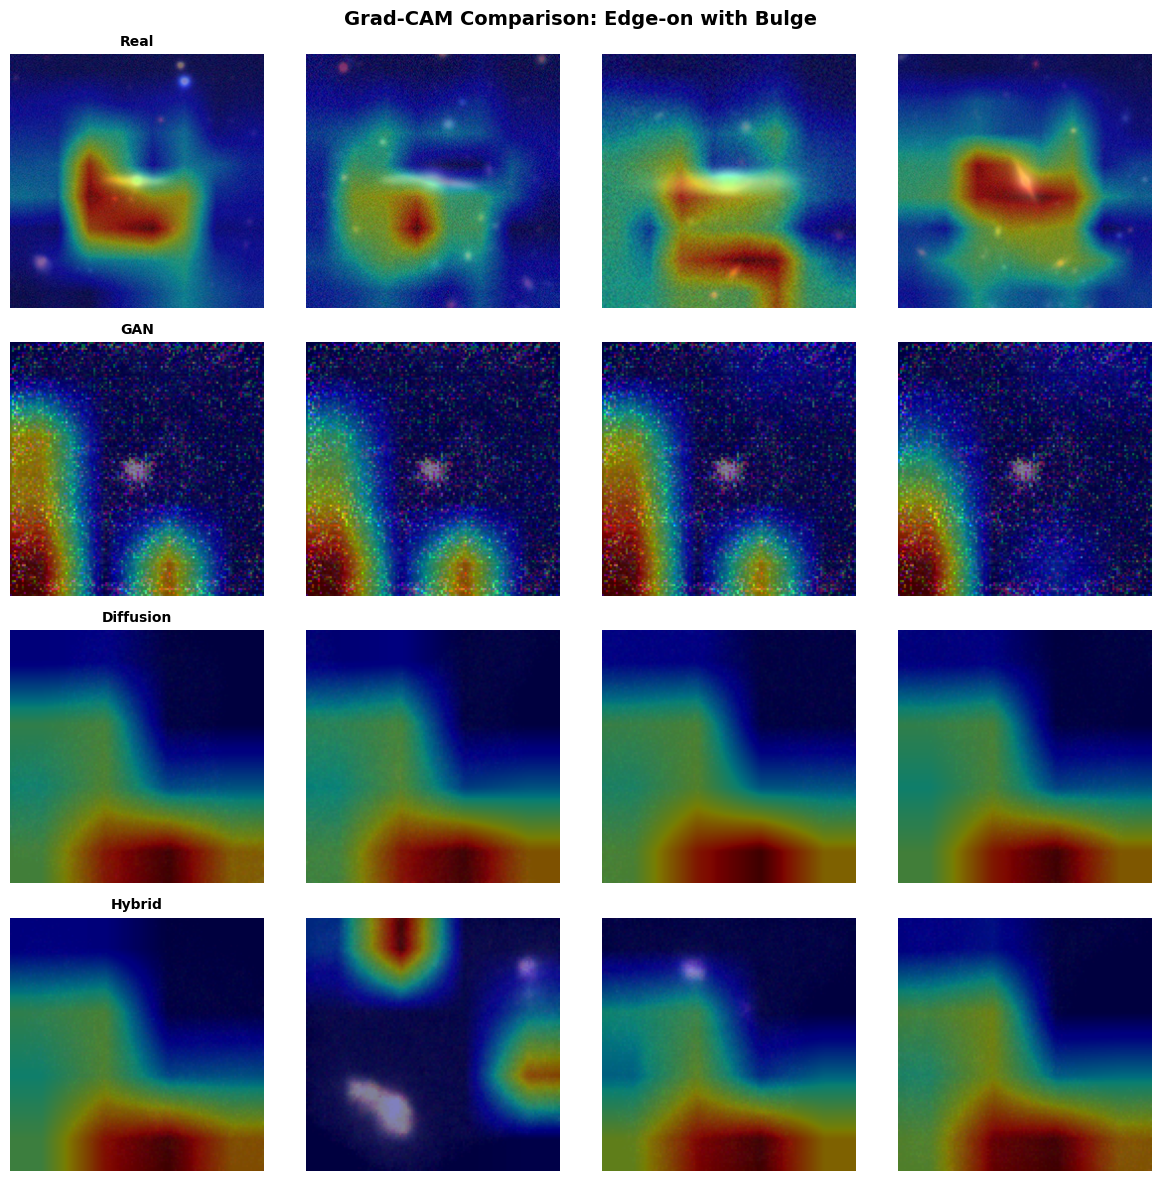


Feature Space Analysis:
  GAN separation:    230.198
  Diff separation:   299.880
  Hybrid separation: 302.908


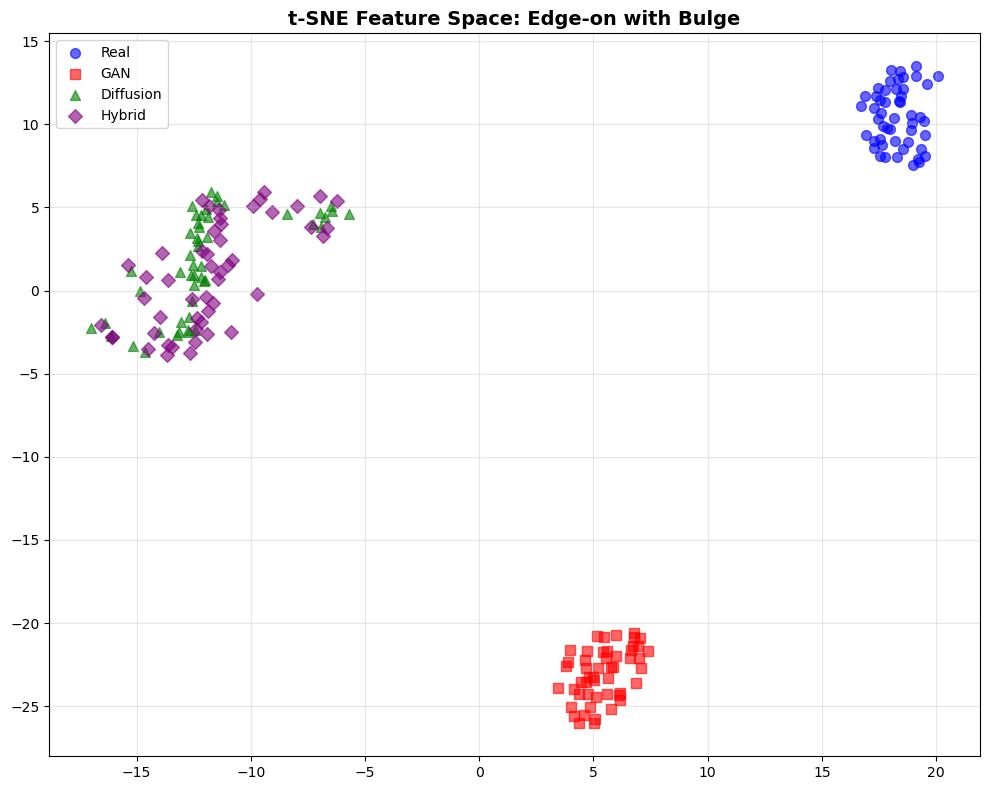


WRONG CLASS CONTROL EXPERIMENT

Feature Space Separation from Real:
  GAN:        384.694
  Hybrid:     340.595
  Wrong-class: 23.034

GAN vs Wrong-class difference:    361.661
Hybrid vs Wrong-class difference: 317.562


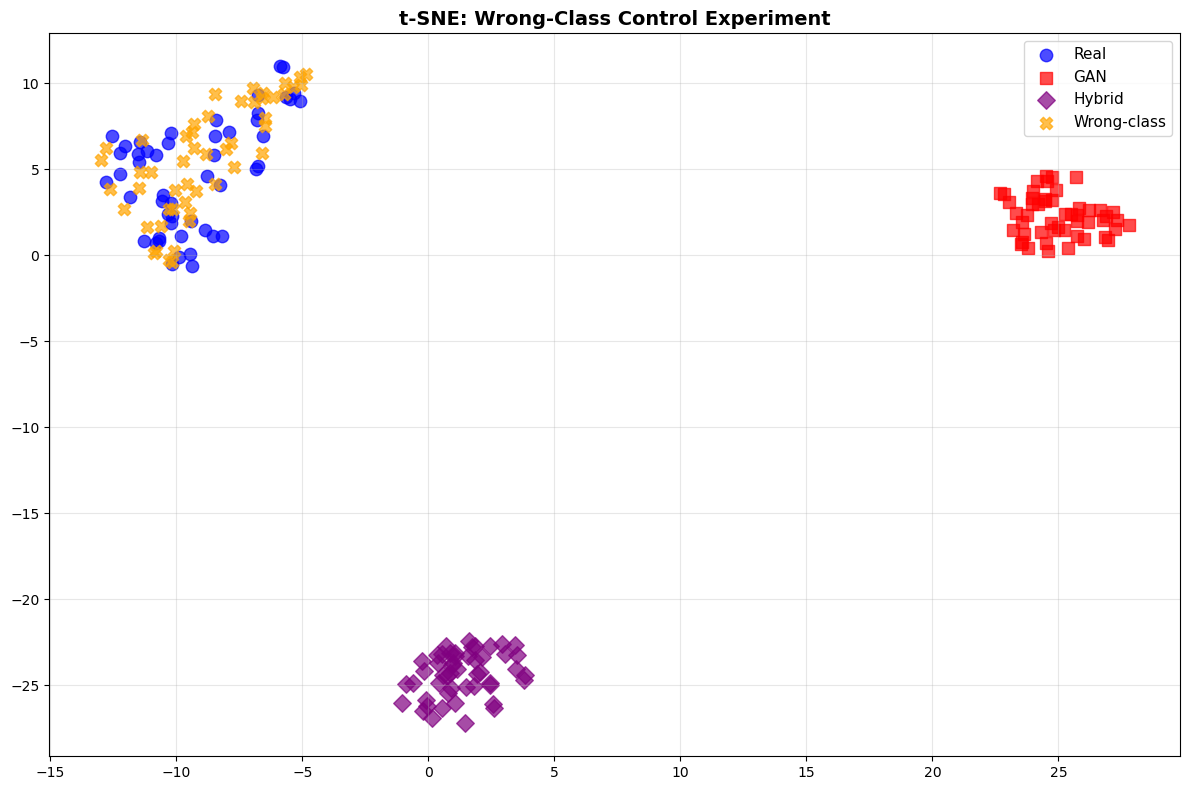

SUMMARY TABLE

Class                          GAN        Diff       Hybrid    
------------------------------------------------------------
Merging Galaxies                  384.7    300.0    340.6
Cigar Shaped Smooth Galaxies      465.5    326.3    412.9
Edge-on without Bulge             323.5    315.9    341.2
Edge-on with Bulge                230.2    299.9    302.9

Control:                          384.7      N/A    340.6
Wrong-class:                       23.0
XAI ANALYSIS COMPLETE


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from scipy.spatial.distance import cosine
from scipy.interpolate import interp1d
import seaborn as sns
import json
import os
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import densenet121

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class_names = [
    'Disturbed Galaxies',
    'Merging Galaxies', 
    'Round Smooth Galaxies',
    'In-between Round Smooth Galaxies',
    'Cigar Shaped Smooth Galaxies',
    'Barred Spiral Galaxies',
    'Unbarred Tight Spiral Galaxies',
    'Unbarred Loose Spiral Galaxies',
    'Edge-on without Bulge',
    'Edge-on with Bulge'
]


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_backward_hook(self.save_gradient)
    
    def save_activation(self, module, input, output):
        self.activations = output.detach()
    
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def generate_cam(self, images, class_idx):
        self.model.eval()
        images = images.to(device)
        
        output = self.model(images)
        self.model.zero_grad()
        
        class_score = output[:, class_idx].sum()
        class_score.backward()
        
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        
        cam = F.interpolate(cam, size=images.shape[2:], mode='bilinear', align_corners=False)
        
        cam_min = cam.view(cam.size(0), -1).min(dim=1)[0].view(-1, 1, 1, 1)
        cam_max = cam.view(cam.size(0), -1).max(dim=1)[0].view(-1, 1, 1, 1)
        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)
        
        return cam.cpu().numpy()


def extract_features(model, dataloader, max_samples=500):
    model.eval()
    features = []
    labels = []
    
    with torch.no_grad():
        for imgs, lbls in dataloader:
            if len(features) * imgs.size(0) >= max_samples:
                break
            
            imgs = imgs.to(device)
            
            x = model.densenet.features(imgs)
            x = F.relu(x, inplace=True)
            x = F.adaptive_avg_pool2d(x, (1, 1))
            x = torch.flatten(x, 1)
            
            features.append(x.cpu())
            labels.append(lbls)
    
    if len(features) == 0:
        return None, None
    
    features = torch.cat(features, dim=0).numpy()
    labels = torch.cat(labels, dim=0).numpy()
    
    return features[:max_samples], labels[:max_samples]

# ============= MORPHOLOGICAL ANALYSIS =============
def analyze_morphology(images, labels, class_idx):
    class_mask = labels == class_idx
    class_images = images[class_mask]
    
    if len(class_images) == 0:
        return None
    
    center_brightness = []
    edge_brightness = []
    asymmetry_scores = []
    
    for img in class_images:
        if img.max() <= 1.0:
            img = (img * 255).astype(np.uint8)
        
        gray = img.mean(axis=-1) if len(img.shape) == 3 else img
        
        center_region = gray[gray.shape[0]//2 - 10:gray.shape[0]//2 + 10, :]
        center_brightness.append(center_region.mean())
        
        edge_left = gray[:, :20].mean()
        edge_right = gray[:, -20:].mean()
        edge_brightness.append((edge_left + edge_right) / 2)
        
        flipped = np.fliplr(gray)
        asymmetry = np.abs(gray - flipped).sum() / gray.sum()
        asymmetry_scores.append(asymmetry)
    
    center_edge_ratio = np.mean(center_brightness) / (np.mean(edge_brightness) + 1e-8)
    
    return {
        'center_edge_ratio': float(center_edge_ratio),
        'mean_asymmetry': float(np.mean(asymmetry_scores)),
        'std_asymmetry': float(np.std(asymmetry_scores))
    }

def calculate_attention_similarity(real_cam, synthetic_cam):
    real_cam_flat = real_cam.reshape(real_cam.shape[0], -1)
    synthetic_cam_flat = synthetic_cam.reshape(synthetic_cam.shape[0], -1)
    
    if np.isnan(real_cam).any() or np.isnan(synthetic_cam).any():
        return np.nan
    if real_cam.std() < 1e-8 or synthetic_cam.std() < 1e-8:
        return np.nan
    
    target_size = min(real_cam_flat.shape[1], synthetic_cam_flat.shape[1])
    
    def resize_cam(cam_flat, target_size):
        if cam_flat.shape[1] == target_size:
            return cam_flat
        result = []
        for row in cam_flat:
            x_old = np.linspace(0, 1, len(row))
            x_new = np.linspace(0, 1, target_size)
            f = interp1d(x_old, row, kind='linear')
            result.append(f(x_new))
        return np.array(result)
    
    real_resized = resize_cam(real_cam_flat, target_size)
    synthetic_resized = resize_cam(synthetic_cam_flat, target_size)
    
    similarities = []
    for r in real_resized:
        for s in synthetic_resized:
            try:
                sim = 1 - cosine(r, s)
                if not np.isnan(sim):
                    similarities.append(sim)
            except:
                continue
    
    return np.mean(similarities) if similarities else np.nan


def analyze_class_full(model, target_class, real_images, real_labels, 
                       gan_images, gan_labels, diff_images, diff_labels,
                       hybrid_images, hybrid_labels, gradcam, save_dir):
    
    os.makedirs(save_dir, exist_ok=True)
    results = {}
    
    print(f"\nCLASS {target_class}: {class_names[target_class]}")
    
    # Prepare loaders
    def prepare_loader(images, labels):
        if images.dtype == np.uint8:
            images = images.astype(np.float32) / 255.0
        tensor = torch.from_numpy(images).permute(0, 3, 1, 2).float()
        labels_tensor = torch.from_numpy(labels).long()
        dataset = TensorDataset(tensor, labels_tensor)
        return DataLoader(dataset, batch_size=16, shuffle=False)
    
    real_loader = prepare_loader(real_images, real_labels)
    gan_loader = prepare_loader(gan_images, gan_labels)
    diff_loader = prepare_loader(diff_images, diff_labels)
    hybrid_loader = prepare_loader(hybrid_images, hybrid_labels)
    
    print(f"Real: {len(real_images)}, GAN: {len(gan_images)}, Diffusion: {len(diff_images)}, Hybrid: {len(hybrid_images)}")
    
    # 1. MORPHOLOGY
    print("\nMorphology Analysis:")
    real_morph = analyze_morphology(real_images, real_labels, target_class)
    gan_morph = analyze_morphology(gan_images, gan_labels, target_class)
    diff_morph = analyze_morphology(diff_images, diff_labels, target_class)
    hybrid_morph = analyze_morphology(hybrid_images, hybrid_labels, target_class)
    
    if real_morph:
        print(f"  Real:    {real_morph['center_edge_ratio']:.3f}")
        print(f"  GAN:     {gan_morph['center_edge_ratio']:.3f} (Δ{abs(gan_morph['center_edge_ratio'] - real_morph['center_edge_ratio'])/real_morph['center_edge_ratio']*100:.1f}%)")
        print(f"  Diff:    {diff_morph['center_edge_ratio']:.3f} (Δ{abs(diff_morph['center_edge_ratio'] - real_morph['center_edge_ratio'])/real_morph['center_edge_ratio']*100:.1f}%)")
        print(f"  Hybrid:  {hybrid_morph['center_edge_ratio']:.3f} (Δ{abs(hybrid_morph['center_edge_ratio'] - real_morph['center_edge_ratio'])/real_morph['center_edge_ratio']*100:.1f}%)")
    
    # 2. GRAD-CAM
    print("\nGrad-CAM Analysis:")
    real_batch = next(iter(real_loader))
    real_imgs = real_batch[0][:4].to(device)
    
    gan_batch = next(iter(gan_loader))
    gan_imgs = gan_batch[0][:4].to(device)
    
    diff_batch = next(iter(diff_loader))
    diff_imgs = diff_batch[0][:4].to(device)
    
    hybrid_batch = next(iter(hybrid_loader))
    hybrid_imgs = hybrid_batch[0][:4].to(device)
    
    real_cam = gradcam.generate_cam(real_imgs, target_class)
    gan_cam = gradcam.generate_cam(gan_imgs, target_class)
    diff_cam = gradcam.generate_cam(diff_imgs, target_class)
    hybrid_cam = gradcam.generate_cam(hybrid_imgs, target_class)
    
    gan_attention_sim = calculate_attention_similarity(real_cam, gan_cam)
    diff_attention_sim = calculate_attention_similarity(real_cam, diff_cam)
    hybrid_attention_sim = calculate_attention_similarity(real_cam, hybrid_cam)
    
    print(f"  GAN similarity:    {gan_attention_sim:.3f}")
    print(f"  Diff similarity:   {diff_attention_sim:.3f}")
    print(f"  Hybrid similarity: {hybrid_attention_sim:.3f}")
    
    # Plot Grad-CAM 
    
    fig, axes = plt.subplots(4, 4, figsize=(12, 12))
    for i in range(4):
        axes[0, i].imshow(real_imgs[i].cpu().permute(1, 2, 0).numpy())
        axes[0, i].imshow(real_cam[i, 0], alpha=0.5, cmap='jet')
        axes[0, i].axis('off')
        if i == 0:
            axes[0, i].set_title('Real', fontsize=10, fontweight='bold')
        
        axes[1, i].imshow(gan_imgs[i].cpu().permute(1, 2, 0).numpy())
        axes[1, i].imshow(gan_cam[i, 0], alpha=0.5, cmap='jet')
        axes[1, i].axis('off')
        if i == 0:
            axes[1, i].set_title('GAN', fontsize=10, fontweight='bold')
        
        axes[2, i].imshow(diff_imgs[i].cpu().permute(1, 2, 0).numpy())
        axes[2, i].imshow(diff_cam[i, 0], alpha=0.5, cmap='jet')
        axes[2, i].axis('off')
        if i == 0:
            axes[2, i].set_title('Diffusion', fontsize=10, fontweight='bold')
        
        axes[3, i].imshow(hybrid_imgs[i].cpu().permute(1, 2, 0).numpy())
        axes[3, i].imshow(hybrid_cam[i, 0], alpha=0.5, cmap='jet')
        axes[3, i].axis('off')
        if i == 0:
            axes[3, i].set_title('Hybrid', fontsize=10, fontweight='bold')
    
    plt.suptitle(f'Grad-CAM Comparison: {class_names[target_class]}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'{save_dir}/gradcam_class_{target_class}_all.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # 3. FEATURE SPACE + t-SNE
    print("\nFeature Space Analysis:")
    real_features, _ = extract_features(model, real_loader, max_samples=100)
    gan_features, _ = extract_features(model, gan_loader, max_samples=100)
    diff_features, _ = extract_features(model, diff_loader, max_samples=100)
    hybrid_features, _ = extract_features(model, hybrid_loader, max_samples=100)
    
    if real_features is not None:
        # Calculate separation
        real_center = real_features.mean(axis=0)
        gan_center = gan_features.mean(axis=0)
        diff_center = diff_features.mean(axis=0)
        hybrid_center = hybrid_features.mean(axis=0)
        
        real_std = real_features.std(axis=0).mean()
        gan_sep = np.linalg.norm(real_center - gan_center) / (real_std + 1e-8)
        diff_sep = np.linalg.norm(real_center - diff_center) / (real_std + 1e-8)
        hybrid_sep = np.linalg.norm(real_center - hybrid_center) / (real_std + 1e-8)
        
        print(f"  GAN separation:    {gan_sep:.3f}")
        print(f"  Diff separation:   {diff_sep:.3f}")
        print(f"  Hybrid separation: {hybrid_sep:.3f}")
        
        # t-SNE plot 
        
        combined_features = np.vstack([real_features, gan_features, diff_features, hybrid_features])
        source_labels = (['Real'] * len(real_features) + 
                        ['GAN'] * len(gan_features) + 
                        ['Diffusion'] * len(diff_features) + 
                        ['Hybrid'] * len(hybrid_features))
        
        tsne = TSNE(n_components=2, random_state=42, perplexity=30)
        tsne_results = tsne.fit_transform(combined_features)
        
        fig, ax = plt.subplots(1, 1, figsize=(10, 8))
        colors = {'Real': 'blue', 'GAN': 'red', 'Diffusion': 'green', 'Hybrid': 'purple'}
        markers = {'Real': 'o', 'GAN': 's', 'Diffusion': '^', 'Hybrid': 'D'}
        for source in ['Real', 'GAN', 'Diffusion', 'Hybrid']:
            mask = [s == source for s in source_labels]
            ax.scatter(tsne_results[mask, 0], tsne_results[mask, 1], 
                      c=colors[source], marker=markers[source], 
                      label=source, alpha=0.6, s=50)
        ax.set_title(f't-SNE Feature Space: {class_names[target_class]}', fontsize=14, fontweight='bold')
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(f'{save_dir}/tsne_class_{target_class}_all.png', dpi=300, bbox_inches='tight')
        plt.show()
    else:
        gan_sep = np.nan
        diff_sep = np.nan
        hybrid_sep = np.nan
    
    results = {
        'class_id': target_class,
        'class_name': class_names[target_class],
        'morphology': {
            'real': real_morph, 
            'gan': gan_morph, 
            'diffusion': diff_morph,
            'hybrid': hybrid_morph
        },
        'attention': {
            'gan_similarity': float(gan_attention_sim), 
            'diffusion_similarity': float(diff_attention_sim),
            'hybrid_similarity': float(hybrid_attention_sim)
        },
        'feature_space': {
            'gan_separation': float(gan_sep), 
            'diffusion_separation': float(diff_sep),
            'hybrid_separation': float(hybrid_sep)
        }
    }
    
    return results





print("COMPREHENSIVE XAI ANALYSIS (INCLUDING HYBRID)")


os.makedirs('results/xai', exist_ok=True)

# Load model
class BaselineClassifier(nn.Module):
    def __init__(self, num_classes=10):
        super(BaselineClassifier, self).__init__()
        self.densenet = densenet121(pretrained=False)
        self.densenet.classifier = nn.Linear(self.densenet.classifier.in_features, num_classes)
    
    def forward(self, x):
        return self.densenet(x)

model = BaselineClassifier()
checkpoint = torch.load('results/baseline/baseline_model.pth', map_location=device)
model.load_state_dict(checkpoint)
model.to(device)
model.eval()

target_layer = None
for name, module in model.named_modules():
    if isinstance(module, nn.Conv2d):
        target_layer = module
gradcam = GradCAM(model, target_layer)

# Load data
data_dir = 'data/processed'
X_test = np.load(f'{data_dir}/X_test.npy')
y_test = np.load(f'{data_dir}/y_test.npy')

gan_images_all = np.load('results/gan/synthetic_images.npy')
gan_labels_all = np.load('results/gan/synthetic_labels.npy')

diff_images_all = np.load('results/diffusion/synthetic_images.npy')
diff_labels_all = np.load('results/diffusion/synthetic_labels.npy')

hybrid_images_all = np.load('results/diffusion_gan/synthetic_images.npy')
hybrid_labels_all = np.load('results/diffusion_gan/synthetic_labels.npy')

minority_classes = [1, 4, 8, 9]
all_results = {}

# Analyze each class
for target_class in minority_classes:
    real_mask = y_test == target_class
    real_images = X_test[real_mask][:50]
    real_labels = y_test[real_mask][:50]
    
    gan_mask = gan_labels_all == target_class
    gan_images = gan_images_all[gan_mask][:50]
    gan_labels = gan_labels_all[gan_mask][:50]
    
    diff_mask = diff_labels_all == target_class
    diff_images = diff_images_all[diff_mask][:50]
    diff_labels = diff_labels_all[diff_mask][:50]
    
    hybrid_mask = hybrid_labels_all == target_class
    hybrid_images = hybrid_images_all[hybrid_mask][:50]
    hybrid_labels = hybrid_labels_all[hybrid_mask][:50]
    
    results = analyze_class_full(model, target_class, real_images, real_labels,
                                 gan_images, gan_labels, diff_images, diff_labels,
                                 hybrid_images, hybrid_labels, gradcam, 'results/xai')
    
    all_results[f'class_{target_class}'] = results



print("WRONG CLASS CONTROL EXPERIMENT")



# Spirals labeled as Merging
spiral_mask = y_test == 5
wrong_images = X_test[spiral_mask][:50]
wrong_labels = np.full(50, 1)

real_mask = y_test == 1
real_images = X_test[real_mask][:50]
real_labels = y_test[real_mask][:50]

gan_mask = gan_labels_all == 1
gan_images = gan_images_all[gan_mask][:50]
gan_labels = gan_labels_all[gan_mask][:50]

hybrid_mask = hybrid_labels_all == 1
hybrid_images = hybrid_images_all[hybrid_mask][:50]
hybrid_labels = hybrid_labels_all[hybrid_mask][:50]

def prepare_loader(images, labels):
    if images.dtype == np.uint8:
        images = images.astype(np.float32) / 255.0
    tensor = torch.from_numpy(images).permute(0, 3, 1, 2).float()
    labels_tensor = torch.from_numpy(labels).long()
    dataset = TensorDataset(tensor, labels_tensor)
    return DataLoader(dataset, batch_size=16, shuffle=False)

real_loader = prepare_loader(real_images, real_labels)
gan_loader = prepare_loader(gan_images, gan_labels)
hybrid_loader = prepare_loader(hybrid_images, hybrid_labels)
wrong_loader = prepare_loader(wrong_images, wrong_labels)

# Feature space
real_features, _ = extract_features(model, real_loader, max_samples=50)
gan_features, _ = extract_features(model, gan_loader, max_samples=50)
hybrid_features, _ = extract_features(model, hybrid_loader, max_samples=50)
wrong_features, _ = extract_features(model, wrong_loader, max_samples=50)

real_center = real_features.mean(axis=0)
gan_center = gan_features.mean(axis=0)
hybrid_center = hybrid_features.mean(axis=0)
wrong_center = wrong_features.mean(axis=0)

real_std = real_features.std(axis=0).mean()
gan_sep = np.linalg.norm(real_center - gan_center) / (real_std + 1e-8)
hybrid_sep = np.linalg.norm(real_center - hybrid_center) / (real_std + 1e-8)
wrong_sep = np.linalg.norm(real_center - wrong_center) / (real_std + 1e-8)

print(f"\nFeature Space Separation from Real:")
print(f"  GAN:        {gan_sep:.3f}")
print(f"  Hybrid:     {hybrid_sep:.3f}")
print(f"  Wrong-class: {wrong_sep:.3f}")
print(f"\nGAN vs Wrong-class difference:    {abs(gan_sep - wrong_sep):.3f}")
print(f"Hybrid vs Wrong-class difference: {abs(hybrid_sep - wrong_sep):.3f}")

# t-SNE for control 

combined = np.vstack([real_features, gan_features, hybrid_features, wrong_features])
labels_plot = (['Real']*len(real_features) + 
               ['GAN']*len(gan_features) + 
               ['Hybrid']*len(hybrid_features) + 
               ['Wrong-class']*len(wrong_features))

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_results = tsne.fit_transform(combined)

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
colors = {'Real': 'blue', 'GAN': 'red', 'Hybrid': 'purple', 'Wrong-class': 'orange'}
markers = {'Real': 'o', 'GAN': 's', 'Hybrid': 'D', 'Wrong-class': 'X'}
for source in ['Real', 'GAN', 'Hybrid', 'Wrong-class']:
    mask = [s == source for s in labels_plot]
    ax.scatter(tsne_results[mask, 0], tsne_results[mask, 1], 
              c=colors[source], marker=markers[source], 
              label=source, alpha=0.7, s=80)
ax.set_title('t-SNE: Wrong-Class Control Experiment', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results/xai/tsne_wrong_class_control_all.png', dpi=300, bbox_inches='tight')
plt.show()

all_results['wrong_class_control'] = {
    'feature_space': {
        'gan_separation': float(gan_sep), 
        'hybrid_separation': float(hybrid_sep),
        'wrong_class_separation': float(wrong_sep)
    }
}

# Save
with open('results/xai/comprehensive_results_all.json', 'w') as f:
    json.dump(all_results, f, indent=2)


print("SUMMARY TABLE")


print(f"\n{'Class':<30} {'GAN':<10} {'Diff':<10} {'Hybrid':<10}")
print("-" * 60)
for key in [f'class_{c}' for c in minority_classes]:
    r = all_results[key]
    print(f"{r['class_name']:<30} {r['feature_space']['gan_separation']:>8.1f} {r['feature_space']['diffusion_separation']:>8.1f} {r['feature_space']['hybrid_separation']:>8.1f}")

print(f"\n{'Control:':<30} {all_results['wrong_class_control']['feature_space']['gan_separation']:>8.1f} {'N/A':>8} {all_results['wrong_class_control']['feature_space']['hybrid_separation']:>8.1f}")
print(f"{'Wrong-class:':<30} {all_results['wrong_class_control']['feature_space']['wrong_class_separation']:>8.1f}")


print("XAI ANALYSIS COMPLETE")
